--- 数据预览 ---
        Date State       Region  Confirmed  Deaths  Recovered
0  4/29/2020   NaN  Afghanistan       1939      60        252
1  4/29/2020   NaN      Albania        766      30        455
2  4/29/2020   NaN      Algeria       3848     444       1702
3  4/29/2020   NaN      Andorra        743      42        423
4  4/29/2020   NaN       Angola         27       2          7

--- 非空值统计 ---
Date         321
State        140
Region       321
Confirmed    321
Deaths       321
Recovered    321
dtype: int64

--- 缺失值统计 ---
Date           0
State        181
Region         0
Confirmed      0
Deaths         0
Recovered      0
dtype: int64


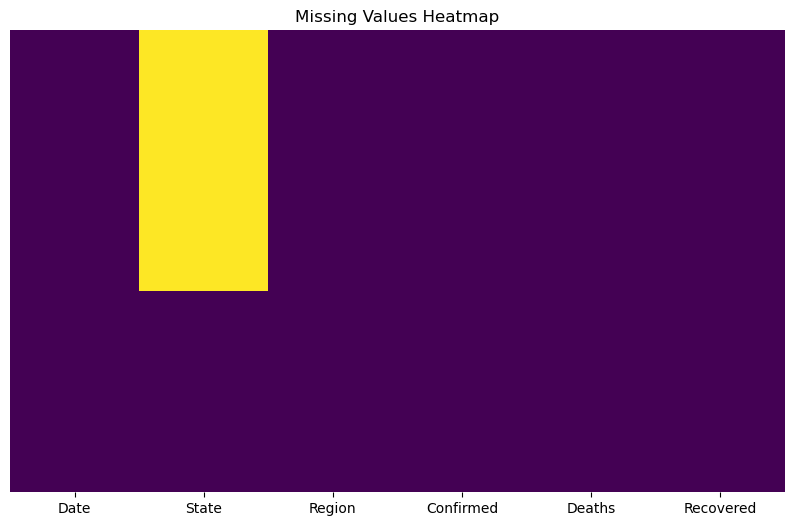

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('4. Covid_19_data.csv')

print("--- 数据预览 ---")
print(df.head())

print("\n--- 非空值统计 ---")
print(df.count())

print("\n--- 缺失值统计 ---")
print(df.isnull().sum())

plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [3]:
region_summary = df.groupby('Region')[['Confirmed', 'Deaths', 'Recovered']].sum()

print("\n--- Q.4-1: 每个 Region 的病例数 ---")
print(region_summary)


--- Q.4-1: 每个 Region 的病例数 ---
                    Confirmed  Deaths  Recovered
Region                                          
Afghanistan              1939      60        252
Albania                   766      30        455
Algeria                  3848     444       1702
Andorra                   743      42        423
Angola                     27       2          7
...                       ...     ...        ...
West Bank and Gaza        344       2         71
Western Sahara              6       0          5
Yemen                       6       0          1
Zambia                     97       3         54
Zimbabwe                   32       4          5

[187 rows x 3 columns]


In [5]:
df_filtered = df[df['Confirmed'] >= 10].copy()  # 使用 copy 避免警告

print(f"\n--- Q.4-2: 删除 Confirmed < 10 后的数据形状 ---")
print(f"原始数据: {df.shape}, 过滤后: {df_filtered.shape}")


--- Q.4-2: 删除 Confirmed < 10 后的数据形状 ---
原始数据: (321, 6), 过滤后: (304, 6)


In [7]:
max_confirmed_region = region_summary['Confirmed'].sort_values(ascending=False).head(1)
print("\n--- Q.4-3: 确诊病例最多的 Region ---")
print(max_confirmed_region)


--- Q.4-3: 确诊病例最多的 Region ---
Region
US    1039909
Name: Confirmed, dtype: int64


In [9]:
min_deaths_region = region_summary['Deaths'].sort_values(ascending=True).head(1)
print("\n--- Q.4-4: 死亡病例最少的 Region ---")
print(min_deaths_region)


--- Q.4-4: 死亡病例最少的 Region ---
Region
Laos    0
Name: Deaths, dtype: int64


In [11]:
india_data = df[df['Region'] == 'India']

print("\n--- Q.4-5: 印度在 2020-04-29 的病例数 ---")
print(india_data[['Confirmed', 'Deaths', 'Recovered']])


--- Q.4-5: 印度在 2020-04-29 的病例数 ---
    Confirmed  Deaths  Recovered
74      33062    1079       8437


In [13]:
df_sorted_asc = df.sort_values(by='Confirmed', ascending=True)

print("\n--- Q.4-6-A: 按 Confirmed 升序排列 (前10行) ---")
print(df_sorted_asc.head(10))


--- Q.4-6-A: 按 Confirmed 升序排列 (前10行) ---
          Date                             State          Region  Confirmed  \
285  4/29/2020                         Recovered              US          0   
284  4/29/2020                         Recovered          Canada          0   
203  4/29/2020      Diamond Princess cruise ship          Canada          0   
305  4/29/2020                             Tibet  Mainland China          1   
289  4/29/2020         Saint Pierre and Miquelon          France          1   
184  4/29/2020                          Anguilla              UK          3   
192  4/29/2020  Bonaire, Sint Eustatius and Saba     Netherlands          5   
272  4/29/2020             Northwest Territories          Canada          5   
288  4/29/2020                  Saint Barthelemy          France          6   
178  4/29/2020                               NaN           Yemen          6   

     Deaths  Recovered  
285       0     120720  
284       0      20327  
203       1  

In [15]:
df_sorted_desc = df.sort_values(by='Recovered', ascending=False)

print("\n--- Q.4-6-B: 按 Recovered 降序排列 (前10行) ---")
print(df_sorted_desc.head(10))


--- Q.4-6-B: 按 Recovered 降序排列 (前10行) ---
          Date      State          Region  Confirmed  Deaths  Recovered
153  4/29/2020        NaN           Spain     236899   24275     132929
285  4/29/2020  Recovered              US          0       0     120720
61   4/29/2020        NaN         Germany     161539    6467     120400
76   4/29/2020        NaN            Iran      93657    5957      73791
80   4/29/2020        NaN           Italy     203591   27682      71252
229  4/29/2020      Hubei  Mainland China      68128    4512      63616
57   4/29/2020        NaN          France     165093   24087      48228
167  4/29/2020        NaN          Turkey     117589    3081      44040
22   4/29/2020        NaN          Brazil      79685    5513      34132
158  4/29/2020        NaN     Switzerland      29407    1716      22600
